# 04 Content based recommender

**Workshop:** LU2 `06_Recommender systems` (Bag of Words, cosine similarity, zoeken op titel).

Een content based recommender vergelijkt **kenmerken van het materiaal** met het **profiel van de student**. Er zijn geen
beoordelingen van anderen nodig, dus het werkt ook voor een nieuwe student (*cold start*).

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from leescoach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from leescoach.content import ContentModel
from leescoach.data_cleaning import load_processed

materials, students, interactions = load_processed()
content = ContentModel().fit(materials)
titles = materials.set_index("cataloguscode")["titel"]

## 1. Cosine similarity tussen materialen

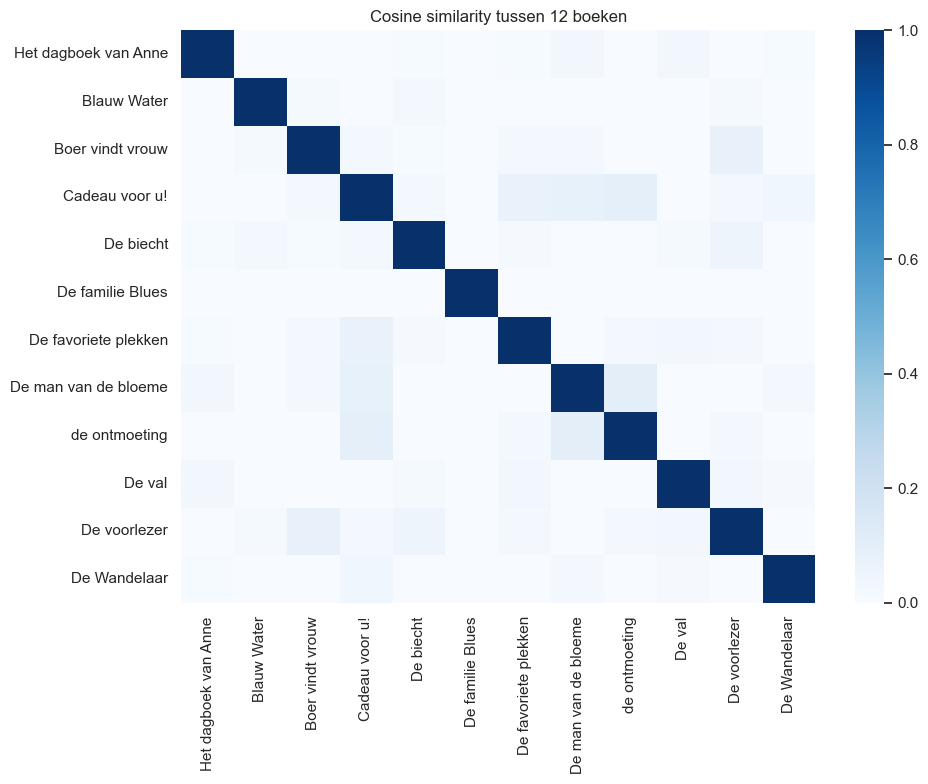

In [3]:
similarity = content.item_similarity()
sample = materials["type"].eq("boek").to_numpy().nonzero()[0][:12]
plt.figure(figsize=(10, 8))
sns.heatmap(similarity[np.ix_(sample, sample)], xticklabels=materials["titel"].iloc[sample].str[:20],
            yticklabels=materials["titel"].iloc[sample].str[:20], cmap="Blues")
plt.title("Cosine similarity tussen 12 boeken")
plt.tight_layout()
plt.show()

## 2. Lijkt op: materialen die op een gekozen titel lijken

In [4]:
def similar_to(title: str, top_n: int = 5) -> pd.DataFrame:
    code = materials.loc[materials["titel"].str.contains(title, case=False), "cataloguscode"].iat[0]
    rows = [(titles[other], round(score, 3)) for other, score in content.similar_items(code, top_n)]
    print("Lijkt op:", titles[code])
    return pd.DataFrame(rows, columns=["titel", "cosine_similarity"])

similar_to("Anne Frank")

Lijkt op: Het dagboek van Anne Frank


,titel,cosine_similarity
0,Het meisje dat er niet mocht zijn,0.134
1,Doe het toch maar,0.110
2,Haar leven,0.103
3,Neem de tijd,0.097
4,De jongen in de gestreepte pyjama,0.073


## 3. Zoeken met een vrije tekst

In [5]:
pd.DataFrame([(titles[code], round(score, 3)) for code, score in content.search("spannend boek over criminaliteit en geheimen")],
             columns=["titel", "score"])

,titel,score
0,Pizzamaffia slaat door,0.267
1,De vijf die blijven,0.153
2,Zonder spijt,0.152
3,Kater,0.146
4,Niet mijn naam,0.146


## 4. Profiel van een student als zoekvraag
Het profiel bestaat uit de interesses (met synoniemen) en, als die er zijn, het gemiddelde van de materialen die de student goed vond.

In [6]:
student = students.iloc[0]
liked = interactions.query("student_id == @student.student_id and voorkeurscore >= 4")["cataloguscode"].tolist()
interests = student["interesses"].split(";")
print("Student", student["student_id"], "interesses:", interests, "| eerder goed gevonden:", len(liked))

scores = pd.Series(content.scores(interests, liked), index=content.codes)
top = scores.drop(index=liked, errors="ignore").nlargest(5)
pd.DataFrame({
    "titel": titles[top.index].to_numpy(),
    "score": top.round(3).to_numpy(),
    "interesse in tekst": [", ".join(content.interest_matches(interests, code)) for code in top.index],
})

Student S001 interesses: ['kunstmatige intelligentie', 'relaties'] | eerder goed gevonden: 7


,titel,score,interesse in tekst
0,Boer vindt vrouw,0.189,relaties
1,Moeder mijn vrouw,0.174,relaties
2,AI-verordening,0.155,kunstmatige intelligentie
3,Een echte man,0.128,relaties
4,Twee Vrouwen,0.111,relaties


## 5. Beperkingen van alleen content based

In [7]:
from leescoach.features import StudentProfile, static_features

profile = StudentProfile.from_dataset_row(student)
check = static_features(profile, materials).loc[top.index, ["niveau_verschil", "type_match", "genre_match", "leestijd_past"]]
check.insert(0, "titel", titles[top.index].to_numpy())
check

,titel,niveau_verschil,type_match,genre_match,leestijd_past
CAT-00003,Boer vindt vrouw,0.0,1.0,0.0,0.0
CAT-00028,Moeder mijn vrouw,1.0,1.0,0.0,0.0
CAT-00142,AI-verordening,1.5,0.0,1.0,1.0
CAT-00013,Een echte man,0.0,1.0,0.0,0.0
CAT-00035,Twee Vrouwen,1.5,1.0,0.0,0.0


Puur op tekst kijken negeert het **niveau**, het **type**, de **leestijd** en wat **andere studenten** ervan vonden.
Een tekstueel perfect boek kan dus te moeilijk of te lang zijn. In notebook 06 combineren we daarom content based scores
met deze kenmerken en met collaborative filtering in een getraind model.